In [1]:
import pandas as pd
import numpy as np
import os
from datetime import datetime
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE # Assurez-vous d'installer imblearn: pip install imbalanced-learn
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc

# --- Configuration ---
DATA_PATH = "/home/kaoutar/Desktop/data/" # Votre chemin confirmé
print(f"Chemin des données : {DATA_PATH}")
OUTPUT_PATH = DATA_PATH # Où sauvegarder les résultats
FINAL_ENGINEERED_FILE = os.path.join(OUTPUT_PATH, 'dataset_final_engineered_complet.csv')

# Pour calculs de date
REFERENCE_DATE = pd.to_datetime(datetime.now())
print(f"Date de référence pour calculs: {REFERENCE_DATE.date()}")

# Paramètres Feature Engineering & Analyse
RARE_CATEGORY_THRESHOLD_PERC = 0.001 # Seuil pour regrouper catégories rares (0.1%)
TOP_N_VISUALIZE = 15 # Pour visualisations catégorielles
N_TOP_FEATURES_DISPLAY = 30 # Pour affichage importance features
HIGH_CARD_COLS = ['ctry_of_birth', 'residence'] # Colonnes à traiter pour haute cardinalité

# Dictionnaire des fichiers sources
files_to_load = {
    'perimeter': ('Périmétre_projet.txt', '|'),
    'credit': ('ACT_CD_CREDIT_MDM28032025.txt', '|'),
    'getchq': ('ACT_CD_GETCHQ_MDM28032025.txt', '|'),
    'operations_agence': ('ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt', ';'),
    'vignette': ('ACT_CD_PAI_VIGNETTE_MDM20032025.txt', '|'),
    'produit': ('ACT_CD_PRODUIT_MDM20032025.txt', '|'),
    'solde': ('ACT_CD_SOLDE_CLIENT_MDM28032025.txt', '|'),
    'connexion': ('ACT_CD_STAT_CONNEXION_MDM28032025.txt', '|'),
    'transa': ('ACT_CD_TRANSA_MDM20032025.txt', '|'),
    'transferts': ('ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt', '|'),
    'equi': ('ACT_EQUI_MDM28032025.txt', '|')
}

Chemin des données : /home/kaoutar/Desktop/data/
Date de référence pour calculs: 2025-04-24


In [2]:
print("\n--- ÉTAPE I: Chargement et Préparation Initiale ---")

# --- Fonctions Utilitaires (Nettoyage, Conversion, ID) ---
def load_file(file_path, separator):
    if not os.path.exists(file_path):
        print(f"ERREUR: Fichier introuvable: {file_path}")
        return None
    encodings = ['utf-8', 'latin1', 'iso-8859-1']
    df = None
    for encoding in encodings:
        try:
            df = pd.read_csv(file_path, sep=separator, encoding=encoding, low_memory=False, on_bad_lines='warn')
            print(f"  Fichier chargé: {os.path.basename(file_path)} (enc: {encoding}, shape: {df.shape})")
            return df
        except Exception: pass
    print(f"ERREUR: Impossible charger {os.path.basename(file_path)}")
    return None

def clean_col_names(df):
    cols = df.columns
    new_cols = [re.sub(r'\s+', '_', re.sub(r'[^\w\s]', '', col.strip().lower())) for col in cols]
    df.columns = new_cols
    return df

def convert_to_numeric(series):
    if pd.api.types.is_numeric_dtype(series): return series
    if series.dtype == 'object':
        cleaned = series.astype(str).str.replace(',', '.', regex=False).str.replace(' ', '', regex=False)
        return pd.to_numeric(cleaned, errors='coerce')
    return series

def convert_to_datetime(series, date_formats=None):
    if pd.api.types.is_datetime64_any_dtype(series): return series
    if date_formats is None: date_formats = ['%d/%m/%Y', '%Y%m%d', '%Y-%m-%d', '%m/%y', '%d/%m/%y']
    original_series = series.copy()
    converted_series = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]') # Init avec NaT
    # Essayer conversion directe d'abord (peut gérer mixtes ou formats standards)
    try_auto = pd.to_datetime(original_series, errors='coerce')
    if try_auto.notna().sum() > 0:
       converted_series = try_auto
       # print(f"    -> Conversion auto a fonctionné pour {try_auto.notna().sum()} valeurs.")

    # Essayer formats spécifiques si auto a échoué ou pour améliorer
    for fmt in date_formats:
        try:
            converted_fmt = pd.to_datetime(original_series, format=fmt, errors='coerce')
            # Remplacer les NaT par les valeurs converties si elles sont meilleures
            mask_converted = converted_fmt.notna()
            if mask_converted.any():
               # print(f"    -> Format '{fmt}' a fonctionné pour {mask_converted.sum()} valeurs.")
               converted_series.loc[mask_converted] = converted_fmt.loc[mask_converted]
        except ValueError: pass # Format invalide

    return converted_series


def standardize_id(series, zfill_len=7):
    if pd.api.types.is_datetime64_any_dtype(series): return series
    id_str = series.fillna('').astype(str).str.strip().str.replace(r'\.0$', '', regex=True)
    is_digit_mask = id_str.str.isdigit() & (id_str != '')
    id_filled = id_str.copy()
    id_filled.loc[is_digit_mask] = id_filled.loc[is_digit_mask].str.zfill(zfill_len)
    id_filled.loc[~is_digit_mask] = np.nan # Mettre NaN si pas digits ou vide
    return id_filled

# --- Boucle de Chargement et Nettoyage ---
dataframes = {}
print("Chargement et nettoyage des fichiers sources...")
for name, (filename, separator) in files_to_load.items():
    filepath = os.path.join(DATA_PATH, filename)
    df = load_file(filepath, separator)
    if df is not None:
        df = clean_col_names(df)
        # Standardiser IDs (radical ou contrat comme customer_id)
        id_col_to_use = None
        if 'radical' in df.columns:
            df['radical'] = standardize_id(df['radical'])
            df.rename(columns={'radical': 'customer_id'}, inplace=True)
            id_col_to_use = 'customer_id'
            # print(f"  ID 'radical' standardisé pour {name}")
        elif 'contrat' in df.columns:
            df['contrat'] = standardize_id(df['contrat'])
            df.rename(columns={'contrat': 'customer_id'}, inplace=True)
            id_col_to_use = 'customer_id'
            # print(f"  ID 'contrat' standardisé pour {name}")
        else:
            print(f"  ATTENTION: Pas d'ID ('radical' ou 'contrat') trouvé dans {name}")

        # Conversion Types (Simplifié : on convertit tout ce qui ressemble)
        potential_date_cols_kws = ['date', 'dt_', '_date', 'mois', 'annee'] # Inclure mois/annee
        potential_numeric_cols_kws = ['montant', 'nombre', 'solde', 'mvt', 'capital', 'duree', 'nbmvt', 'count', 'imp']

        for col in df.columns:
            if col != id_col_to_use: # Ne pas convertir l'ID
                 is_potential_date = any(kw in col for kw in potential_date_cols_kws)
                 is_potential_num = any(kw in col for kw in potential_numeric_cols_kws)

                 if is_potential_date:
                     # print(f"    -> Date? {col}")
                     df[col] = convert_to_datetime(df[col])
                 elif is_potential_num and df[col].dtype == 'object':
                     # print(f"    -> Num? {col}")
                     df[col] = convert_to_numeric(df[col])

        dataframes[name] = df

print(f"\nDataFrames chargés et prétraités: {list(dataframes.keys())}")



--- ÉTAPE I: Chargement et Préparation Initiale ---
Chargement et nettoyage des fichiers sources...
  Fichier chargé: Périmétre_projet.txt (enc: utf-8, shape: (1051499, 8))
  Fichier chargé: ACT_CD_CREDIT_MDM28032025.txt (enc: utf-8, shape: (32835, 11))


/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')


  Fichier chargé: ACT_CD_GETCHQ_MDM28032025.txt (enc: utf-8, shape: (144032, 4))
  Fichier chargé: ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt (enc: utf-8, shape: (3846343, 5))
  Fichier chargé: ACT_CD_PAI_VIGNETTE_MDM20032025.txt (enc: utf-8, shape: (438507, 4))


/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')


  Fichier chargé: ACT_CD_PRODUIT_MDM20032025.txt (enc: latin1, shape: (1737390, 7))
  Fichier chargé: ACT_CD_SOLDE_CLIENT_MDM28032025.txt (enc: utf-8, shape: (11005299, 8))
  Fichier chargé: ACT_CD_STAT_CONNEXION_MDM28032025.txt (enc: utf-8, shape: (9791515, 6))


/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')
/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')


  Fichier chargé: ACT_CD_TRANSA_MDM20032025.txt (enc: utf-8, shape: (929381, 6))


/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  try_auto = pd.to_datetime(original_series, errors='coerce')


  Fichier chargé: ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt (enc: utf-8, shape: (668439, 5))
  Fichier chargé: ACT_EQUI_MDM28032025.txt (enc: utf-8, shape: (446586, 6))


/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')
/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')
/tmp/ipykernel_4498/1627683678.py:38: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  try_auto = pd.to_datetime(original_series, errors='coerce')



DataFrames chargés et prétraités: ['perimeter', 'credit', 'getchq', 'operations_agence', 'vignette', 'produit', 'solde', 'connexion', 'transa', 'transferts', 'equi']


In [3]:
# --- Créer la table de mapping CONTRAT -> RADICAL (customer_id) (AVEC DEBUG) ---
id_map = None
if 'perimeter' in dataframes:
     df_p_map = dataframes['perimeter'].copy()

     # --- AJOUT DU PRINT DE DEBUG ---
     print("\n--- DEBUG: Colonnes dans df_p_map (perimeter nettoyé) ---")
     print(df_p_map.columns.tolist())
     print("--- FIN DEBUG ---\n")
     # -------------------------------

     # Le 'customer_id' de perimeter est le RADICAL standardisé (fait lors du chargement)
     # Il faut standardiser 'contrat' ici pour le mapping
     id_col_name_contrat = 'contrat' # Nom attendu après nettoyage
     id_col_name_radical = 'customer_id' # Nom créé à partir de radical

     # Vérification qui échoue probablement
     if id_col_name_contrat in df_p_map.columns and id_col_name_radical in df_p_map.columns:
         print(f"OK: Colonnes '{id_col_name_radical}' et '{id_col_name_contrat}' trouvées.") # Message de succès
         df_p_map['contrat_std'] = standardize_id(df_p_map[id_col_name_contrat])
         id_map = df_p_map[[id_col_name_radical, 'contrat_std']].dropna().drop_duplicates(subset=['contrat_std'], keep='first')
         print(f"Table de mapping Contrat -> Customer_ID (Radical) créée. Shape: {id_map.shape}")
         # ... (optional duplicate check) ...
     else:
          # Afficher quelle(s) colonne(s) manque(nt)
          missing_cols_msg = []
          if id_col_name_contrat not in df_p_map.columns:
              missing_cols_msg.append(f"'{id_col_name_contrat}'")
          if id_col_name_radical not in df_p_map.columns:
               missing_cols_msg.append(f"'{id_col_name_radical}'")
          print(f"ERREUR: Colonne(s) {', '.join(missing_cols_msg)} non trouvée(s) dans 'perimeter' pour créer le mapping.")
          print("Vérifiez les noms de colonnes affichés dans le DEBUG ci-dessus et ajustez 'id_col_name_contrat' ou 'id_col_name_radical' si nécessaire.")

else:
     print("Table 'perimeter' non trouvée, impossible de créer le mapping Contrat -> Radical.")


--- DEBUG: Colonnes dans df_p_map (perimeter nettoyé) ---
['customer_id', 'genre', 'statut_marital', 'date_of_birth', 'ctry_of_birth', 'residence', 'cr_profil', 'customer_since']
--- FIN DEBUG ---

ERREUR: Colonne(s) 'contrat' non trouvée(s) dans 'perimeter' pour créer le mapping.
Vérifiez les noms de colonnes affichés dans le DEBUG ci-dessus et ajustez 'id_col_name_contrat' ou 'id_col_name_radical' si nécessaire.


In [5]:
# --- Assurez-vous que REFERENCE_DATE est bien définie ici ---
REFERENCE_DATE = pd.to_datetime(datetime.now())
# ----------------------------------------------------------

def handle_dates(df):
    """Convertit les colonnes de dates, filtre les dates hors limites,
       et crée des features Age et Ancienneté."""
    print("\n--- Traitement des dates ---") # Message pour vérifier si la fonction est appelée
    date_cols = ['date_of_birth', 'customer_since'] # Noms en minuscules après clean_col_names

    min_birth_date = pd.Timestamp('1900-01-01')
    max_birth_date = REFERENCE_DATE
    min_customer_date = pd.Timestamp('1950-01-01')
    max_customer_date = REFERENCE_DATE

    for col in date_cols:
        if col in df.columns:
            # print(f"Traitement de la colonne date: {col}") # Décommenter pour debug
            original_dtype = df[col].dtype
            df[col] = convert_to_datetime(df[col]) # Utilise la fonction convert_to_datetime définie plus haut

            # Filtrer les dates hors limites
            if pd.api.types.is_datetime64_any_dtype(df[col]):
                if col == 'date_of_birth':
                    min_valid_date, max_valid_date = min_birth_date, max_birth_date
                elif col == 'customer_since':
                    min_valid_date, max_valid_date = min_customer_date, max_customer_date
                else:
                    min_valid_date, max_valid_date = pd.Timestamp('1678-01-01'), pd.Timestamp('2261-12-31')

                out_of_range_mask = ~df[col].isna() & ((df[col] < min_valid_date) | (df[col] > max_valid_date))
                num_out_of_range = out_of_range_mask.sum()

                if num_out_of_range > 0:
                    print(f"  Attention: {num_out_of_range} dates dans '{col}' hors plage ({min_valid_date.date()} - {max_valid_date.date()}) mises à NaT.")
                    df.loc[out_of_range_mask, col] = pd.NaT
            # else:
            #    print(f"  Attention: Colonne {col} non datetime après conversion.")

        # else:
        #     print(f"  Colonne date '{col}' non trouvée.")


    # Création de l'âge
    if 'date_of_birth' in df.columns and pd.api.types.is_datetime64_any_dtype(df['date_of_birth']):
        delta_age = REFERENCE_DATE - df['date_of_birth']
        df['age'] = (delta_age.dt.days / 365.2425)
        df['age'] = df['age'].round(1)
        df.loc[df['age'] < 0, 'age'] = np.nan # Remettre nom en minuscule 'age'
        if df['age'].isna().any():
             age_median = df['age'].median()
             if pd.notna(age_median) and age_median > 0 and age_median < 110:
                 df['age'].fillna(age_median, inplace=True)

    # Création de l'ancienneté client
    if 'customer_since' in df.columns and pd.api.types.is_datetime64_any_dtype(df['customer_since']):
        delta_tenure = REFERENCE_DATE - df['customer_since']
        df['customer_tenure_years'] = (delta_tenure.dt.days / 365.2425) # Remettre nom en minuscule
        df['customer_tenure_years'] = df['customer_tenure_years'].round(1)
        df.loc[df['customer_tenure_years'] < 0, 'customer_tenure_years'] = 0
        if df['customer_tenure_years'].isna().any():
             tenure_median = df['customer_tenure_years'].median()
             if pd.notna(tenure_median) and tenure_median >= 0:
                 df['customer_tenure_years'].fillna(tenure_median, inplace=True)

    return df
# --- 3.1 Dataset de Base (Périmètre) et Features Démographiques ---
if 'perimeter' not in dataframes:
    raise ValueError("DataFrame 'perimeter' est essentiel et n'a pas été chargé.")
else:
    df_base = dataframes['perimeter'].copy()
    # Assurer que customer_id est bien le nom standard
    if 'customer_id' not in df_base.columns:
        if 'radical' in df_base.columns:
             df_base['radical'] = standardize_id(df_base['radical'])
             df_base.rename(columns={'radical': 'customer_id'}, inplace=True)
        else:
             raise ValueError("Impossible de trouver 'customer_id' ou 'radical' dans perimeter.")
    df_base = df_base.drop_duplicates(subset=['customer_id'], keep='first') # Assurer unicité client

    print(f"Utilisation de 'perimeter' comme base. Shape unique: {df_base.shape}")
    # Calculer AGE et TENURE
    df_base = handle_dates(df_base) # Réutilise la fonction pour convertir dates + créer Age/Tenure

    # Nettoyer/Imputer démo
    demo_cols = ['genre', 'statut_marital', 'ctry_of_birth', 'residence', 'cr_profil']
    for col in demo_cols:
        if col in df_base.columns: df_base[col].fillna('Missing', inplace=True)


# --- 3.2 Agrégation des Données Comportementales par Client ---
print("\nAgrégation des données comportementales (peut prendre du temps)...")
aggregated_features = {}
all_customer_ids = df_base['customer_id'].unique() # Liste de tous les clients du périmètre

# Fonction pour agréger et stocker
# Fonction pour agréger et stocker AVEC DEBUG PRINTS
# Fonction pour agréger et stocker (Version Simplifiée et Corrigée)
def aggregate_and_store(df_name, agg_dict, time_col=None):
    # Id attendu est TOUJOURS 'customer_id' maintenant
    id_col = 'customer_id'
    print(f"\n--- Début Agrégation pour: {df_name} ---")

    if df_name in dataframes:
        df = dataframes[df_name].copy()
        # Vérifier si l'ID client existe
        if id_col in df.columns:
            print(f"  OK: Colonne ID '{id_col}' trouvée.")

            # Calculer la date la plus récente si time_col spécifié AVANT le groupby
            last_date_map = None
            if time_col and time_col in df.columns:
                df[time_col] = convert_to_datetime(df[time_col]) # Assurer format date
                if pd.api.types.is_datetime64_any_dtype(df[time_col]):
                    last_dates = df.loc[df[time_col].notna()].groupby(id_col)[time_col].max()
                    last_date_map = last_dates

            # Filtrer les lignes où l'ID est NaN avant groupby
            df_filtered = df.dropna(subset=[id_col])
            if df_filtered.empty:
                 print(f"  ATTENTION: Aucun ID valide pour {df_name}. Agrégation vide.")
                 df_agg = pd.DataFrame(columns=[id_col] + list(agg_dict.keys())) # Créer vide avec colonnes
            else:
                print(f"  Exécution de groupby sur '{id_col}'...")
                try:
                    df_agg = df_filtered.groupby(id_col).agg(**agg_dict).reset_index()
                    print(f"  Groupby terminé. Shape intermédiaire: {df_agg.shape}")
                except Exception as e:
                    print(f"  ERREUR pendant .agg() pour {df_name}: {e}")
                    print(f"  Colonnes disponibles pour agg: {df_filtered.columns}")
                    # Créer df vide pour ne pas bloquer la suite
                    df_agg = pd.DataFrame(columns=[id_col] + list(agg_dict.keys()))


            # Ajouter temps depuis dernier événement
            if last_date_map is not None and not df_agg.empty and f'{df_name}_days_since_last' not in df_agg.columns: # Eviter recréation
                df_agg[f'{df_name}_days_since_last'] = df_agg[id_col].map(last_date_map)
                if pd.api.types.is_datetime64_any_dtype(df_agg[f'{df_name}_days_since_last']):
                    df_agg[f'{df_name}_days_since_last'] = (REFERENCE_DATE - df_agg[f'{df_name}_days_since_last']).dt.days
                else:
                    df_agg[f'{df_name}_days_since_last'] = np.nan
                df_agg[f'{df_name}_days_since_last'].fillna(-1, inplace=True)

            # Garder uniquement les clients du périmètre (déjà fait dans df_base, mais sécurité)
            # S'assurer que all_customer_ids est défini globalement ou passé en argument
            if 'all_customer_ids' in globals() and not df_agg.empty:
                 df_agg = df_agg[df_agg[id_col].isin(all_customer_ids)]

            # S'assurer que la colonne ID est bien 'customer_id' (normalement déjà le cas)
            if id_col in df_agg.columns:
                aggregated_features[df_name] = df_agg
                print(f"  -> Agrégats '{df_name}' créés et stockés. Shape finale agrégat: {df_agg.shape}")
                return True
            else:
                 print(f"  ERREUR: Colonne '{id_col}' manquante à la fin de l'agrégation pour {df_name}!")
                 print(f"--- Fin Agrégation (ÉCHEC) pour: {df_name} ---")
                 return False
        else:
             print(f"  ERREUR: La colonne ID '{id_col}' n'a PAS été trouvée dans df_{df_name} !")
             print(f"--- Fin Agrégation (ÉCHEC) pour: {df_name} ---")
             return False
    else:
         print(f"  ERREUR: DataFrame '{df_name}' non trouvé.")
         print(f"--- Fin Agrégation (ÉCHEC) pour: {df_name} ---")
         return False
# Définir les agrégations pour chaque table (AJUSTER SI NÉCESSAIRE !)
agg_solde = {
    'solde_m': ('solde', 'mean'), 'solde_std': ('solde', 'std'), 'solde_med': ('solde', 'median'),
    'mvtcred_m': ('mvtcred', 'mean'), 'mvtdeb_m': ('mvtdeb', 'mean'),
    'mvtcred_tot': ('mvtcred', 'sum'), 'mvtdeb_tot': ('mvtdeb', 'sum'),
    'nbmvtc_m': ('nbmvtcre_mens', 'mean'), 'nbmvtd_m': ('nbmvtdb_mens', 'mean'),
    'nbmvtc_tot': ('nbmvtcre_mens', 'sum'), 'nbmvtd_tot': ('nbmvtdb_mens', 'sum'),
    'nb_mois': ('mois', 'count')
}
aggregate_and_store('solde', agg_solde)

agg_ops_agence = {
    'ops_agence_montant_tot': ('montant', lambda x: x.abs().sum()), # Somme des valeurs absolues
    'ops_agence_montant_m': ('montant', lambda x: x.abs().mean()),
    'ops_agence_nb_op_tot': ('nombre_operation', 'sum'),
    'ops_agence_nb_op_m': ('nombre_operation', 'mean'),
    'ops_agence_nb_mois': ('mois', 'count')
}
aggregate_and_store('operations_agence', agg_ops_agence)

agg_transa = {
    'dig_nb_op_tot': ('nombre_ope', 'sum'),
    'dig_montant_tot': ('montant_total', 'sum'),
    'dig_montant_m': ('montant_total', 'mean'),
    'dig_nb_sessions': ('dt_confirmation', 'count'),
    'dig_nb_type_ope_distinct': ('type_ope', 'nunique')
}
aggregate_and_store('transa', agg_transa, time_col='dt_confirmation')

agg_produit = {
    'nb_produits': ('code_prd', 'nunique'),
    # Flag pour produit 'BLADI' (exemple)
    'has_bladi': ('lib_prd', lambda x: (x == 'BLADI').any().astype(int))
}
aggregate_and_store('produit', agg_produit)

agg_transferts = {
    'transf_montant_tot': ('montant', 'sum'),
    'transf_montant_m': ('montant', 'mean'),
    'transf_nb_tot': ('nombre', 'sum'),
    'transf_nb_m': ('nombre', 'mean'),
    'transf_nb_mois': ('mois', 'count')
}
aggregate_and_store('transferts', agg_transferts)

agg_credit = {
    'credit_nb': ('nodoss', 'count'),
    'credit_montant_tot': ('montant', 'sum'),
    'credit_montant_m': ('montant', 'mean'),
    'credit_duree_m': ('duree', 'mean'),
    'credit_has_immo': ('type', lambda x: (x == 'Immobilier').any().astype(int)) # Flag Immo
}
aggregate_and_store('credit', agg_credit, time_col='date_octroi')

agg_getchq = {'getchq_count': ('type_ope', 'count')}
aggregate_and_store('getchq', agg_getchq, time_col='dt_enr') # Utilise contrat

agg_vignette = {
    'vignette_count': ('login', 'count'),
    'vignette_montant_tot': ('montant_total', 'sum'),
    'vignette_montant_m': ('montant_total', 'mean')
}
aggregate_and_store('vignette', agg_vignette, time_col='dt_create')

agg_equi = {
    'is_sub_valid': ('etat', lambda x: ((x == 2) | (x == '2')).any().astype(int)) # Check si au moins 1 est valide (2 ou '2')
}
aggregate_and_store('equi', agg_equi, time_col='date_val_abon') # Utiliser date validation?

# Dictionnaire d'agrégation pour connexion CORRIGÉ
agg_connexion = {
    'connect_count_raw': ('connectioncount', 'sum'), # Assure-toi que connectioncount est numérique
    'connect_locked': ('islockedout', 'any'), # Utiliser directement 'any'
    'connect_ever_success': ('connection', lambda x: x.str.contains('Reussi', na=False).any()), # La lambda renvoie True/False
    'connect_different_dates': ('createdate', lambda x: x.nunique() > 1) # La lambda renvoie True/False
}
# ATTENTION: connexion utilise CONTRAT, nécessite mapping ou jointure spécifique
# Pour simplifier ici, on suppose que l'ID est déjà mappé à customer_id si présent
aggregate_and_store('connexion', agg_connexion, time_col='lastlogindate')


# --- 3.3 Joindre les Agrégats au DataFrame de Base ---
print("\nJointure des features agrégées...")
df_merged = df_base.copy()
for name, df_agg in aggregated_features.items():
    if 'customer_id' in df_agg.columns:
        # print(f"  Jointure avec '{name}'...")
        df_merged = pd.merge(df_merged, df_agg, on='customer_id', how='left')
print(f"Shape après toutes les jointures: {df_merged.shape}")

# --- 3.4 Gérer les NaNs Post-Jointure (Amélioré) ---
print("\nGestion des NaNs après jointure...")

# Remplacer NaN par 0 pour comptes, sommes, flags ET colonnes de connexion attendues
# (même si l'agrégation a réussi, certaines colonnes pourraient être NaN si le client n'a pas d'historique connexion)
count_sum_flag_cols = [col for col in df_merged.columns if
                       'nb_' in col or '_nb' in col or 'count' in col or '_tot' in col or
                       'has_' in col or 'is_' in col or '_flag' in col or '_locked' in col or
                       '_success' in col or 'connect_' in col] # Cible spécifiquement les colonnes connexion
for col in count_sum_flag_cols:
    if df_merged[col].isna().any():
        # print(f"  Remplissage NaN par 0 pour (count/sum/flag): {col}")
        # Utiliser .loc pour éviter FutureWarning
        df_merged[col] = df_merged[col].fillna(0)


# Remplacer NaN par 0 pour moyennes, std, min, max
stat_cols = [col for col in df_merged.columns if
             '_m' in col or '_std' in col or '_med' in col or
             '_min' in col or '_max' in col or '_duree' in col]
for col in stat_cols:
    if df_merged[col].isna().any():
        # print(f"  Remplissage NaN par 0 pour (stat): {col}")
        # Utiliser .loc pour éviter FutureWarning
        df_merged[col] = df_merged[col].fillna(0) # Remplacer par 0 est simple, la médiane serait mieux si possible

# Remplacer NaN par -1 pour temps depuis dernier événement
days_since_cols = [col for col in df_merged.columns if 'days_since' in col]
for col in days_since_cols:
     if df_merged[col].isna().any():
        # print(f"  Remplissage NaN par -1 pour (days_since): {col}")
        # Utiliser .loc pour éviter FutureWarning
        df_merged[col] = df_merged[col].fillna(-1)

# Conversion explicite des colonnes connexion (qui étaient bool avant agg) en int après fillna
connect_bool_cols = ['connect_locked', 'connect_ever_success', 'connect_different_dates']
for col in connect_bool_cols:
    if col in df_merged.columns:
         # S'assurer que c'est numérique (0.0/1.0 après fillna(0)) puis convertir en int
         if pd.api.types.is_numeric_dtype(df_merged[col]):
             df_merged[col] = df_merged[col].astype(int)
         else: # Au cas où ce serait encore un autre type
             # Tenter une conversion directe True->1 / False->0
             try:
                df_merged[col] = df_merged[col].map({True: 1, False: 0, 1:1, 0:0}).fillna(0).astype(int)
             except:
                print(f"Impossible de convertir {col} en int, remplissage par 0.")
                df_merged[col] = 0


nan_check_3_4 = df_merged.isna().sum().sum()
print(f"  NaN restants après remplissage (devrait être 0): {nan_check_3_4}")
if nan_check_3_4 > 0:
     print("  Colonnes avec NaN restants:")
     print(df_merged.isna().sum()[df_merged.isna().sum() > 0])
# --- 3.5 Créer les Indicateurs Booléens Finaux et la Cible (Corrigé) ---
print("\nCréation des indicateurs booléens finaux et de la cible (version robuste)...")

# Fonction utilitaire pour créer les flags
def create_flag(df, new_col_name, source_col_name, condition_func):
    if source_col_name in df.columns:
        df[new_col_name] = condition_func(df[source_col_name]).astype(int)
    else:
        print(f"ATTENTION: Colonne source '{source_col_name}' non trouvée pour créer '{new_col_name}'. Mise à 0.")
        df[new_col_name] = 0 # Default to 0 if source column is missing

# Créer les flags en utilisant la fonction
create_flag(df_merged, 'has_transaction', 'dig_nb_op_tot', lambda x: x > 0)
create_flag(df_merged, 'used_getchq', 'getchq_count', lambda x: x > 0)
create_flag(df_merged, 'paid_vignette', 'vignette_count', lambda x: x > 0)
create_flag(df_merged, 'validated_subscription', 'is_sub_valid', lambda x: x > 0) # is_sub_valid est déjà 0/1
create_flag(df_merged, 'connected', 'connect_ever_success', lambda x: x > 0) # connect_ever_success est déjà 0/1

# Définir la cible appetent (utilise les flags créés ci-dessus)
df_merged['appetent'] = (
    (df_merged['validated_subscription'] == 1) &
    (
        (df_merged['has_transaction'] == 1) |
        (df_merged['used_getchq'] == 1) |
        (df_merged['paid_vignette'] == 1)
    )
).astype(int)

print("Indicateurs et cible créés.")
print(f"Distribution de la cible 'appetent':\n{df_merged['appetent'].value_counts(normalize=True) * 100}")

# --- 3.6 Encoder les Catégorielles (avec regroupement) ---
print("\nEncodage des variables catégorielles finales...")
categorical_cols_final = ['genre', 'statut_marital', 'ctry_of_birth', 'residence', 'cr_profil']
# Ajouter ici d'autres catégorielles créées si nécessaire

df_to_encode = df_merged.copy()

# Regroupement rares
threshold_count_final = int(len(df_to_encode) * RARE_CATEGORY_THRESHOLD_PERC)
print(f"  Regroupement des catégories rares (< {threshold_count_final} occurrences)")
for col in categorical_cols_final:
    if col in df_to_encode.columns and col in HIGH_CARD_COLS:
        counts = df_to_encode[col].value_counts()
        rare_categories = counts[counts < threshold_count_final].index.tolist()
        if rare_categories:
             # print(f"  '{col}': {len(rare_categories)} regroupées.")
             df_to_encode[col] = df_to_encode[col].replace(rare_categories, 'Other_Country')
    # Assurer que la colonne existe avant l'encodage
    if col not in df_to_encode.columns:
        print(f"  ATTENTION: Colonne {col} non trouvée pour encodage.")
        categorical_cols_final.remove(col)


df_encoded_final = pd.get_dummies(df_to_encode,
                                   columns=[c for c in categorical_cols_final if c in df_to_encode.columns],
                                   prefix=categorical_cols_final, # Donne des noms clairs
                                   prefix_sep='_',
                                   drop_first=False, dummy_na=False)
print(f"  Shape après One-Hot Encoding final: {df_encoded_final.shape}")

# --- 3.7 Nettoyage Final (Restructuré) ---
print("\nNettoyage final du DataFrame...")

# Définir les colonnes à supprimer
cols_to_drop_final = ['customer_id'] # Supprimer ID client final
# Ajouter les colonnes de date originales (elles contiennent les NaNs restants)
original_date_cols = ['date_of_birth', 'customer_since']
for col in original_date_cols:
    if col in df_encoded_final.columns:
        cols_to_drop_final.append(col)

# Ajouter les colonnes de date issues des agrégations si non désirées comme features
date_agg_cols = [col for col in df_encoded_final if 'days_since_last' in col or '_last_date' in col] # Adapter si autres noms
cols_to_drop_final.extend(date_agg_cols)

# Supprimer has_any_action si créé
if 'has_any_action' in df_encoded_final.columns: cols_to_drop_final.append('has_any_action')

# Créer df_engineered en supprimant les colonnes
existing_cols_to_drop = [col for col in cols_to_drop_final if col in df_encoded_final.columns]
if existing_cols_to_drop:
    print(f"  Colonnes supprimées: {existing_cols_to_drop}")
    df_engineered = df_encoded_final.drop(columns=existing_cols_to_drop)
else:
     print("  Aucune colonne spécifiée à supprimer trouvée.")
     df_engineered = df_encoded_final.copy() # Assigner df_engineered dans tous les cas

# MAINTENANT, travailler sur df_engineered qui est défini

# Conversion finale des colonnes booléennes restantes en int
print("  Conversion finale des colonnes booléennes en int...")
bool_cols_to_convert = df_engineered.select_dtypes(include='bool').columns
if len(bool_cols_to_convert) > 0:
    print(f"  Colonnes bool converties en int: {bool_cols_to_convert.tolist()}")
    for col in bool_cols_to_convert:
         df_engineered[col] = df_engineered[col].astype(int)
else:
    print("  Aucune colonne booléenne restante à convertir.")

# Vérification finale des types (après conversion bool->int)
print("  Vérification finale des types...")
if 'appetent' in df_engineered.columns:
     X_check = df_engineered.drop('appetent', axis=1)
else: X_check = df_engineered.copy() # Si target déjà séparé
non_numeric_cols = X_check.select_dtypes(exclude=[np.number]).columns
if len(non_numeric_cols) > 0:
    print(f"  ATTENTION Finale: Colonnes non numériques restantes dans les features: {non_numeric_cols.tolist()}")
else:
    print("  Vérification finale des types: OK (toutes features numériques).")

# Vérification finale des NaNs (après drop des colonnes date)
print("  Vérification finale des NaNs...")
final_nan_check = df_engineered.isna().sum().sum()
if final_nan_check == 0: print("  Vérification finale NaNs: OK (0 NaN)")
else:
    print(f"  ATTENTION Finale: {final_nan_check} NaN restants !")
    print("  Colonnes avec NaN restants à la fin:")
    print(df_engineered.isna().sum()[df_engineered.isna().sum() > 0])

print(f"\nShape finale du DataFrame 'df_engineered': {df_engineered.shape}")
print("\n--- Feature Engineering Terminé ---")
# print(df_engineered.head())
# df_engineered.info()

# Sauvegarde
print(f"\nSauvegarde du DataFrame final dans: {FINAL_ENGINEERED_FILE}")
try:
    df_engineered.to_csv(FINAL_ENGINEERED_FILE, index=False, sep=',')
    print("  Sauvegarde réussie.")
except Exception as e:
    print(f"  ERREUR lors de la sauvegarde: {e}")

Utilisation de 'perimeter' comme base. Shape unique: (1051281, 8)

--- Traitement des dates ---
  Attention: 27 dates dans 'date_of_birth' hors plage (1900-01-01 - 2025-04-24) mises à NaT.
  Attention: 1 dates dans 'customer_since' hors plage (1950-01-01 - 2025-04-24) mises à NaT.


/tmp/ipykernel_4498/855439964.py:53: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(age_median, inplace=True)
/tmp/ipykernel_4498/855439964.py:64: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 


Agrégation des données comportementales (peut prendre du temps)...

--- Début Agrégation pour: solde ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (1043713, 13)
  -> Agrégats 'solde' créés et stockés. Shape finale agrégat: (1043713, 13)

--- Début Agrégation pour: operations_agence ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (545232, 6)
  -> Agrégats 'operations_agence' créés et stockés. Shape finale agrégat: (545232, 6)

--- Début Agrégation pour: transa ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (77173, 6)


/tmp/ipykernel_4498/855439964.py:142: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_agg[f'{df_name}_days_since_last'].fillna(-1, inplace=True)


  -> Agrégats 'transa' créés et stockés. Shape finale agrégat: (77173, 7)

--- Début Agrégation pour: produit ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (859461, 3)
  -> Agrégats 'produit' créés et stockés. Shape finale agrégat: (801160, 3)

--- Début Agrégation pour: transferts ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (109373, 6)
  -> Agrégats 'transferts' créés et stockés. Shape finale agrégat: (109373, 6)

--- Début Agrégation pour: credit ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (31138, 6)
  -> Agrégats 'credit' créés et stockés. Shape finale agrégat: (31138, 7)

--- Début Agrégation pour: getchq ---


/tmp/ipykernel_4498/855439964.py:142: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_agg[f'{df_name}_days_since_last'].fillna(-1, inplace=True)


... (5 outputs left out)

/tmp/ipykernel_4498/855439964.py:142: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_agg[f'{df_name}_days_since_last'].fillna(-1, inplace=True)


  -> Agrégats 'equi' créés et stockés. Shape finale agrégat: (421198, 3)

--- Début Agrégation pour: connexion ---
  OK: Colonne ID 'customer_id' trouvée.
  Exécution de groupby sur 'customer_id'...
  Groupby terminé. Shape intermédiaire: (251454, 5)


/tmp/ipykernel_4498/855439964.py:142: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_agg[f'{df_name}_days_since_last'].fillna(-1, inplace=True)


  -> Agrégats 'connexion' créés et stockés. Shape finale agrégat: (251454, 6)

Jointure des features agrégées...
Shape après toutes les jointures: (1051281, 59)

Gestion des NaNs après jointure...
  NaN restants après remplissage (devrait être 0): 3597
  Colonnes avec NaN restants:
date_of_birth     1431
customer_since    2166
dtype: int64

Création des indicateurs booléens finaux et de la cible (version robuste)...
Indicateurs et cible créés.
Distribution de la cible 'appetent':
appetent
0    92.3968
1     7.6032
Name: proportion, dtype: float64

Encodage des variables catégorielles finales...
  Regroupement des catégories rares (< 1051 occurrences)
  Shape après One-Hot Encoding final: (1051281, 107)

Nettoyage final du DataFrame...
  Colonnes supprimées: ['customer_id', 'date_of_birth', 'customer_since', 'transa_days_since_last', 'credit_days_since_last', 'getchq_days_since_last', 'vignette_days_since_last', 'equi_days_since_last', 'connexion_days_since_last']
  Conversion finale de


--- ÉTAPE IV: Analyse et Sélection des Features ---
Shape X avant filtrage variance: (1051281, 97)
Dimensions pour Analyse Importance - X: (1051281, 97), y: (1051281,)

Analyse 1: Scores Statistiques Univariés...
  Scores F-value calculés pour 42 colonnes numériques.
  Scores Chi2 calculés pour 55 colonnes catégorielles/booléennes (non-négatives).

--- Top 30 Features (Statistiques Univariées) ---
dig_nb_type_ope_distinct    3.897229e+06
has_transaction             9.237875e+05
dig_nb_sessions             5.436769e+05
connect_ever_success        3.276039e+05
connected                   3.276039e+05
dig_montant_m               2.286894e+05
dig_nb_op_tot               1.936613e+05
dig_montant_tot             1.612071e+05
ops_agence_nb_mois          1.520663e+05
is_sub_valid                1.475767e+05
nbmvtd_m                    1.156400e+05
nbmvtd_tot                  9.930189e+04
ops_agence_nb_op_m          9.367877e+04
used_getchq                 9.153211e+04
connect_locked          

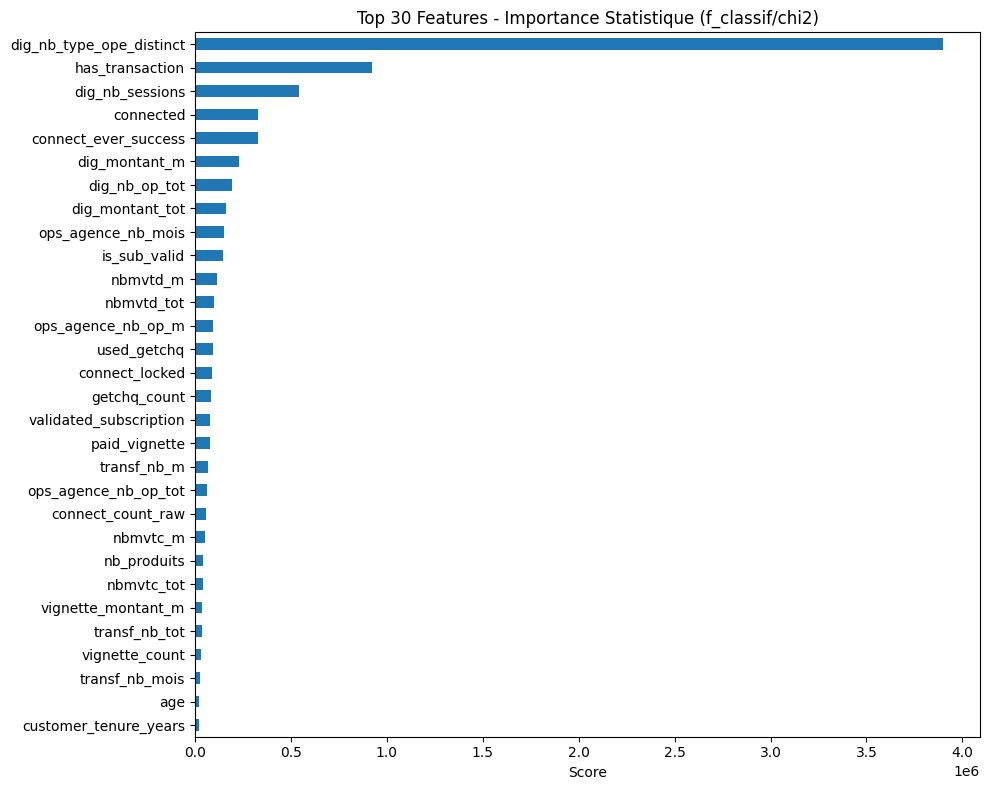


--- Analyse 2: Importance via RandomForest ---
  Entraînement RF pour importance...
  Entraînement terminé.

--- Top 30 Features (RandomForest Importance) ---
dig_nb_op_tot               0.114622
dig_nb_type_ope_distinct    0.106321
dig_nb_sessions             0.102354
dig_montant_tot             0.096638
dig_montant_m               0.084439
has_transaction             0.072015
connect_count_raw           0.071370
connect_ever_success        0.061224
connected                   0.058486
validated_subscription      0.033878
is_sub_valid                0.027221
used_getchq                 0.023668
getchq_count                0.022157
ops_agence_montant_tot      0.021833
ops_agence_montant_m        0.017929
ops_agence_nb_op_tot        0.013327
ops_agence_nb_op_m          0.013243
ops_agence_nb_mois          0.013089
mvtcred_tot                 0.006358
nbmvtd_m                    0.005973
mvtdeb_m                    0.005851
vignette_count              0.003820
vignette_montant_m        

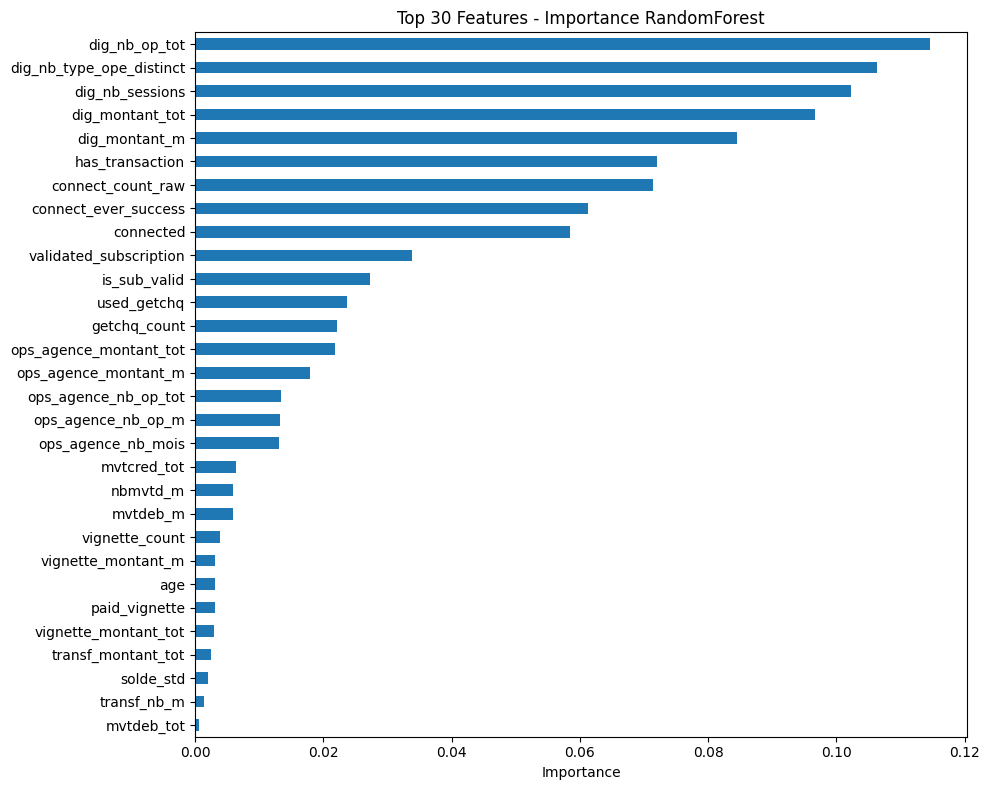


--- Sélection du Jeu de Features Final ---
ATTENTION: Décision cruciale ici basée sur l'objectif métier.
Exemple pour Objectif A: Prédire l'appétence future SANS utiliser les actions la définissant.
Pour Objectif A, 92 features seraient utilisées (X_final).
Si Objectif B (comprendre état actuel), garder toutes les features (X).
Jeu de features final (X_final) sélectionné pour la suite (Objectif A). Shape: (1051281, 92)

--- ÉTAPE V: Préparation Avant Modélisation ---
Séparation Train/Test (80/20)...
  Shapes - Train: (841024, 92), Test: (210257, 92)

Application de SMOTE sur les données d'entraînement...
  Shape Train après SMOTE: (1554158, 92)
  Distribution Cible Train après SMOTE:
appetent
0    50.0
1    50.0
Name: proportion, dtype: float64

Mise à l'échelle (StandardScaler)...
  Scaling des colonnes: ['age', 'customer_tenure_years', 'solde_m', 'solde_std', 'solde_med', 'mvtcred_m', 'mvtdeb_m', 'mvtcred_tot', 'mvtdeb_tot', 'nbmvtc_m', 'nbmvtd_m', 'nbmvtc_tot', 'nbmvtd_tot', 'nb_mo

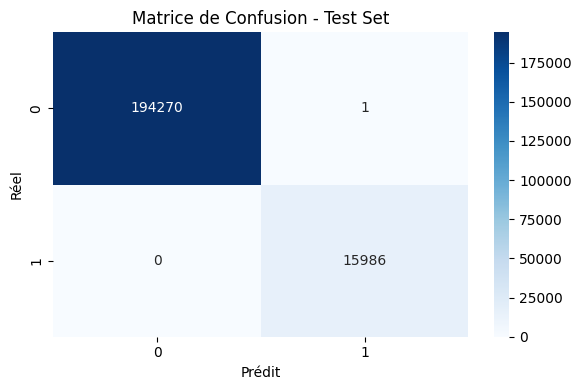


AUC ROC (Test): 1.0000
AUC PR (Test): 1.0000

--- ÉTAPE VII: Interprétation et Déploiement ---
Utiliser des outils comme SHAP sur 'rf_final_model' et 'X_test_scaled' pour interpréter.
Préparer le pipeline complet pour le déploiement.

--- FIN DU SCRIPT COMPLET CORRIGÉ ---


In [6]:

# =============================================================================
# ÉTAPE IV : ANALYSE ET SÉLECTION DES FEATURES
# =============================================================================
print("\n--- ÉTAPE IV: Analyse et Sélection des Features ---")
if 'df_engineered' not in locals():
     # ... (recharger df_engineered) ...
     pass

if 'appetent' in df_engineered.columns:
    X = df_engineered.drop('appetent', axis=1)
    y = df_engineered['appetent']
    X = X.select_dtypes(include=[np.number]) # Garder seulement numériques

    # --- AJOUT : Filtrer colonnes à variance nulle ---
    print(f"Shape X avant filtrage variance: {X.shape}")
    cols_before_var_filt = X.columns
    variance = X.var()
    cols_to_keep = variance[variance > 1e-6].index # Seuil > 0
    X = X[cols_to_keep]
    cols_after_var_filt = X.columns
    dropped_cols_var = cols_before_var_filt.difference(cols_after_var_filt)
    if not dropped_cols_var.empty:
        print(f"  Colonnes à variance nulle/quasi-nulle supprimées de X: {dropped_cols_var.tolist()}")
    print(f"Dimensions pour Analyse Importance - X: {X.shape}, y: {y.shape}")
    # -----------------------------------------------

    # --- Analyse 1: Scores Statistiques ---
    print("\nAnalyse 1: Scores Statistiques Univariés...")
    # Ajuster la détection des colonnes après filtrage et type conversion
    numerical_cols_final = X.select_dtypes(include='float').columns # Float pour Age/Tenure/Stats
    categorical_bool_cols_final = X.select_dtypes(include='int').columns.tolist() # Int pour Flags/Encoded

    scores_num = pd.Series(dtype=float)
    if not numerical_cols_final.empty:
        selector_num = SelectKBest(score_func=f_classif, k='all')
        selector_num.fit(X[numerical_cols_final], y)
        scores_num = pd.Series(selector_num.scores_, index=numerical_cols_final)
        print(f"  Scores F-value calculés pour {len(scores_num)} colonnes numériques.")
    else:
         print("  Aucune colonne float trouvée pour f_classif.")

    scores_cat = pd.Series(dtype=float)
    if categorical_bool_cols_final:
         X_cat_bool = X[categorical_bool_cols_final]
         # Chi2 ne prend pas de négatif (-1 pour days_since_last) -> Utiliser MinMaxScaler ou ignorer ces colonnes pour Chi2
         cols_for_chi2 = [c for c in categorical_bool_cols_final if not (X_cat_bool[c] < 0).any()]
         neg_cols = [c for c in categorical_bool_cols_final if (X_cat_bool[c] < 0).any()]
         if neg_cols: print(f"  Colonnes exclues de Chi2 car négatives: {neg_cols}")

         if cols_for_chi2:
              selector_cat = SelectKBest(score_func=chi2, k='all')
              selector_cat.fit(X[cols_for_chi2], y)
              scores_cat = pd.Series(selector_cat.scores_, index=cols_for_chi2)
              print(f"  Scores Chi2 calculés pour {len(scores_cat)} colonnes catégorielles/booléennes (non-négatives).")
         else:
             print("  Aucune colonne valide trouvée pour Chi2.")
    else:
         print("  Aucune colonne int/bool trouvée pour Chi2.")

    all_scores_stat = pd.concat([scores_num, scores_cat]).sort_values(ascending=False)
    print(f"\n--- Top {N_TOP_FEATURES_DISPLAY} Features (Statistiques Univariées) ---")
    # Afficher seulement si des scores ont été calculés
    if not all_scores_stat.empty:
         print(all_scores_stat.head(N_TOP_FEATURES_DISPLAY))
         # Visualisation
         plt.figure(figsize=(10, 8))
         all_scores_stat.head(N_TOP_FEATURES_DISPLAY).sort_values(ascending=True).plot(kind='barh')
         plt.title(f'Top {N_TOP_FEATURES_DISPLAY} Features - Importance Statistique (f_classif/chi2)')
         plt.xlabel('Score')
         plt.tight_layout()
         plt.show()
    else:
         print("Aucun score statistique n'a pu être calculé.")


    # --- Analyse 2: Importance via RandomForest ---
    print(f"\n--- Analyse 2: Importance via RandomForest ---")
    model_rf_importance = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
    print("  Entraînement RF pour importance...")
    # S'assurer que X ne contient plus de NaN (normalement déjà fait)
    X_rf = X.copy() # Utiliser le X filtré pour variance
    nan_in_X_rf = X_rf.isna().sum().sum()
    if nan_in_X_rf > 0:
        print(f"  ATTENTION: {nan_in_X_rf} NaNs trouvés dans X avant entraînement RF. Remplissage avec 0...")
        X_rf = X_rf.fillna(0)

    model_rf_importance.fit(X_rf, y) # Utiliser X_rf potentiellement fillna
    print("  Entraînement terminé.")

    importances_rf = pd.Series(model_rf_importance.feature_importances_, index=X_rf.columns)
    top_importances_rf = importances_rf.sort_values(ascending=False)

    print(f"\n--- Top {N_TOP_FEATURES_DISPLAY} Features (RandomForest Importance) ---")
    print(top_importances_rf.head(N_TOP_FEATURES_DISPLAY))

    # Visualisation
    plt.figure(figsize=(10, 8))
    top_importances_rf.head(N_TOP_FEATURES_DISPLAY).sort_values(ascending=True).plot(kind='barh')
    plt.title(f'Top {N_TOP_FEATURES_DISPLAY} Features - Importance RandomForest')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()


    # --- Décision sur le Jeu de Features Final (Exemple Objectif A) ---
    print("\n--- Sélection du Jeu de Features Final ---")
    print("ATTENTION: Décision cruciale ici basée sur l'objectif métier.")
    print("Exemple pour Objectif A: Prédire l'appétence future SANS utiliser les actions la définissant.")
    cols_to_remove_for_goal_A = [
        'has_transaction', 'validated_subscription', 'used_getchq', 'paid_vignette',
        'connected', # Optionnel: retirer 'connected'
        # Ajouter les colonnes sources *agrégées* si elles sont jugées trop directes aussi
        # Ex: 'transa_dig_nb_op_tot', 'equi_is_sub_valid', etc.
        # C'est un choix délicat. Pour commencer, on retire juste les flags finaux.
        'transa_dig_nb_op_tot', 'getchq_getchq_count', 'vignette_vignette_count',
        'equi_is_sub_valid', 'connexion_connect_ever_success' # Retirer aussi les sources agrégées des flags
    ]
    features_for_goal_A = [col for col in X.columns if col not in cols_to_remove_for_goal_A]
    print(f"Pour Objectif A, {len(features_for_goal_A)} features seraient utilisées (X_final).")

    print("Si Objectif B (comprendre état actuel), garder toutes les features (X).")
    # Définir X_final basé sur l'objectif choisi
    X_final = X[features_for_goal_A].copy() # Utiliser subset pour Objectif A
    y_final = y.copy()
    print(f"Jeu de features final (X_final) sélectionné pour la suite (Objectif A). Shape: {X_final.shape}")

else:
    print("Erreur: Impossible de continuer l'étape IV sans la colonne cible 'appetent'.")


# =============================================================================
# ÉTAPE V : PRÉPARATION AVANT MODÉLISATION
# =============================================================================
print("\n--- ÉTAPE V: Préparation Avant Modélisation ---")

if 'X_final' in locals() and 'y_final' in locals():
    # 1. Séparation Train/Test
    print("Séparation Train/Test (80/20)...")
    X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.2,
                                                        random_state=42, stratify=y_final)
    print(f"  Shapes - Train: {X_train.shape}, Test: {X_test.shape}")

    # 2. Gestion du Déséquilibre (SMOTE sur Train)
    print("\nApplication de SMOTE sur les données d'entraînement...")
    smote = SMOTE(random_state=42) # CORRECTION: n_jobs retiré
    try:
        X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
        print(f"  Shape Train après SMOTE: {X_train_resampled.shape}")
        print(f"  Distribution Cible Train après SMOTE:\n{pd.Series(y_train_resampled).value_counts(normalize=True)*100}")
    except Exception as e:
        print(f"  ERREUR pendant SMOTE: {e}. Utilisation des données originales.")
        X_train_resampled, y_train_resampled = X_train, y_train

    # 3. Mise à l'échelle (Scaling)
    print("\nMise à l'échelle (StandardScaler)...")
    # Identifier numériques sur X_final (le subset choisi)
    numerical_cols_to_scale = X_final.select_dtypes(include=np.number).columns
    bool_int_cols = X_final.select_dtypes(include=['bool', 'int']).columns
    numerical_cols_to_scale = [c for c in numerical_cols_to_scale if c not in bool_int_cols and c in X_train.columns] # Check existence in X_train

    if numerical_cols_to_scale:
         scaler = StandardScaler()
         X_train_scaled = X_train_resampled.copy()
         X_test_scaled = X_test.copy()
         print(f"  Scaling des colonnes: {numerical_cols_to_scale}")
         # Fitter sur Train (resampled)
         X_train_scaled[numerical_cols_to_scale] = scaler.fit_transform(X_train_scaled[numerical_cols_to_scale])
         # Transformer sur Test
         X_test_scaled[numerical_cols_to_scale] = scaler.transform(X_test_scaled[numerical_cols_to_scale])
         print("  Scaling appliqué.")
    else:
         print("  Aucune colonne numérique (float) à scaler trouvée dans X_final.")
         X_train_scaled = X_train_resampled.copy()
         X_test_scaled = X_test.copy()
else:
    print("Erreur: X_final ou y_final non définis pour l'étape V.")


# =============================================================================
# ÉTAPE VI : ENTRAÎNEMENT ET ÉVALUATION (Exemple RandomForest)
# =============================================================================
print("\n--- ÉTAPE VI: Entraînement et Évaluation (Exemple RandomForest) ---")

if 'X_train_scaled' in locals() and 'y_train_resampled' in locals() and 'X_test_scaled' in locals() and 'y_test' in locals():
    print("\nEntraînement RandomForest Final...")
    rf_final_model = RandomForestClassifier(n_estimators=100,
                                          random_state=42,
                                          n_jobs=-1, # n_jobs est OK pour RandomForest
                                          class_weight=None, # Pas besoin si SMOTE utilisé
                                          max_depth=15,
                                          min_samples_leaf=5)

    rf_final_model.fit(X_train_scaled, y_train_resampled)
    print("  Entraînement terminé.")

    print("\nÉvaluation sur le jeu de Test:")
    y_pred_test = rf_final_model.predict(X_test_scaled)
    y_proba_test = rf_final_model.predict_proba(X_test_scaled)[:, 1]

    print("\nClassification Report (Test):")
    print(classification_report(y_test, y_pred_test, zero_division=0))

    print("\nMatrice de Confusion (Test):")
    cm = confusion_matrix(y_test, y_pred_test)
    print(cm)
    try:
        plt.figure(figsize=(6,4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Prédit')
        plt.ylabel('Réel')
        plt.title('Matrice de Confusion - Test Set')
        plt.tight_layout()
        plt.show()
    except Exception as e: print(f"  Erreur affichage heatmap: {e}")

    try:
         roc_auc = roc_auc_score(y_test, y_proba_test)
         print(f"\nAUC ROC (Test): {roc_auc:.4f}")
    except ValueError as e:
         # Gérer le cas où une seule classe est présente dans y_test (peu probable mais possible)
         print(f"  Impossible de calculer AUC ROC: {e}")
         roc_auc = np.nan

    try:
         precision, recall, _ = precision_recall_curve(y_test, y_proba_test)
         pr_auc = auc(recall, precision)
         print(f"AUC PR (Test): {pr_auc:.4f}")
    except ValueError as e:
        print(f"  Impossible de calculer AUC PR: {e}")
        pr_auc = np.nan

else:
    print("Erreur: Données d'entraînement/test non disponibles pour l'étape VI.")


# =============================================================================
# ÉTAPE VII : INTERPRÉTATION ET DÉPLOIEMENT
# =============================================================================
print("\n--- ÉTAPE VII: Interprétation et Déploiement ---")
print("Utiliser des outils comme SHAP sur 'rf_final_model' et 'X_test_scaled' pour interpréter.")
print("Préparer le pipeline complet pour le déploiement.")


print("\n--- FIN DU SCRIPT COMPLET CORRIGÉ ---")

In [10]:
print("Colonnes dans X_final (potentiellement avec leaks):")
print(sorted(X_final.columns.tolist()))

Colonnes dans X_final (potentiellement avec leaks):
['age', 'connect_count_raw', 'connect_different_dates', 'connect_ever_success', 'connect_locked', 'cr_profil_MDM.MIGRANT.ETABLI', 'cr_profil_MDM.NATIF', 'cr_profil_MDM.NOUVEAU.MIGRANT', 'cr_profil_MDM.SENIOR', 'cr_profil_Missing', 'credit_duree_m', 'credit_has_immo', 'credit_montant_m', 'credit_montant_tot', 'credit_nb', 'ctry_of_birth_BE', 'ctry_of_birth_DE', 'ctry_of_birth_ES', 'ctry_of_birth_FR', 'ctry_of_birth_GB', 'ctry_of_birth_IT', 'ctry_of_birth_MA', 'ctry_of_birth_Missing', 'ctry_of_birth_NL', 'ctry_of_birth_Other_Country', 'ctry_of_birth_XX', 'customer_tenure_years', 'dig_montant_m', 'dig_montant_tot', 'dig_nb_op_tot', 'dig_nb_sessions', 'dig_nb_type_ope_distinct', 'genre_Féminin', 'genre_Masculin', 'genre_Missing', 'getchq_count', 'has_bladi', 'is_sub_valid', 'mvtcred_m', 'mvtcred_tot', 'mvtdeb_m', 'mvtdeb_tot', 'nb_mois', 'nb_produits', 'nbmvtc_m', 'nbmvtc_tot', 'nbmvtd_m', 'nbmvtd_tot', 'ops_agence_montant_m', 'ops_agence

In [9]:
# =============================================================================
# ÉTAPE IV : ANALYSE ET SÉLECTION DES FEATURES - AVEC COMPARAISON
# =============================================================================
print("\n--- ÉTAPE IV: Analyse et Sélection des Features (Avec Comparaison Leaky vs Clean) ---")

# --- Charger/Assurer df_engineered est disponible ---
if 'df_engineered' not in locals() or df_engineered.empty:
     if os.path.exists(FINAL_ENGINEERED_FILE):
         print(f"Rechargement de {FINAL_ENGINEERED_FILE}...")
         df_engineered = pd.read_csv(FINAL_ENGINEERED_FILE)
     else:
         raise FileNotFoundError(f"Le fichier {FINAL_ENGINEERED_FILE} n'existe pas.")

if 'appetent' not in df_engineered.columns:
    raise ValueError("Colonne cible 'appetent' non trouvée.")

# --- Préparer X complet et y (cible originale) ---
X_complet = df_engineered.drop('appetent', axis=1)
y = df_engineered['appetent']
X_complet = X_complet.select_dtypes(include=[np.number]) # Garder seulement numériques

# --- Filtrer variance nulle (une seule fois sur X_complet) ---
print(f"\nShape X_complet avant filtrage variance: {X_complet.shape}")
cols_before_var_filt = X_complet.columns
variance = X_complet.var()
cols_to_keep = variance[(variance > 1e-6) & variance.notna()].index
X = X_complet[cols_to_keep].copy() # Utiliser X pour la suite des analyses/sélections
cols_after_var_filt = X.columns
dropped_cols_var = cols_before_var_filt.difference(cols_after_var_filt)
if not dropped_cols_var.empty:
    print(f"  Colonnes à variance nulle/quasi-nulle supprimées de X: {dropped_cols_var.tolist()}")
print(f"Dimensions pour Analyse Importance - X: {X.shape}, y: {y.shape}")

# --- Analyse d'Importance Initiale (Statistique et RF - comme avant) ---
# (Cette analyse justifie pourquoi on doit retirer des colonnes pour l'Objectif A)
print("\n--- Analyse d'Importance Initiale (sur X avec toutes features post-variance) ---")
# ... (Insérer ici le code de 'Analyse 1: Scores Statistiques' d'avant) ...
# ... (Insérer ici le code de 'Analyse 2: Importance via RandomForest' d'avant) ...
# (Les résultats montreront la dominance des features leaky)


# --- SCÉNARIO 1 : Modélisation avec Fuite (Dataset "Leaky" ~92 col) ---
print("\n--- SCÉNARIO 1 : Modélisation sur jeu de données avec fuite ('Leaky') ---")

# Définir la liste INCOMPLÈTE de colonnes à retirer (celle qui menait aux 92 features et score parfait)
# !! Assurez-vous que ces noms correspondent aux colonnes DANS X !!
cols_to_remove_leaky = [
    'has_transaction', 'validated_subscription', 'used_getchq', 'paid_vignette',
    'connected',
    # Ajouter les 5 agrégats sources directs (vérifier les noms préfixés dans X.columns !)
    'transa_dig_nb_op_tot', 'getchq_getchq_count', 'vignette_vignette_count',
    'equi_is_sub_valid', 'connexion_connect_ever_success'
]
cols_actually_in_X_to_remove_leaky = list(set([col for col in cols_to_remove_leaky if col in X.columns]))
print(f"Colonnes retirées pour Scénario Leaky: {len(cols_actually_in_X_to_remove_leaky)}")
features_leaky = [col for col in X.columns if col not in cols_actually_in_X_to_remove_leaky]
X_final_leaky = X[features_leaky].copy()
y_final_leaky = y.copy() # Même cible
print(f"Shape X_final_leaky: {X_final_leaky.shape}") # Devrait être proche de 92 features

# --- Exécuter Étapes V et VI pour le Scénario Leaky ---
print("\n--- Exécution Étapes V et VI pour Scénario Leaky ---")
if not X_final_leaky.empty:
    # V.1 Split
    X_train_L, X_test_L, y_train_L, y_test_L = train_test_split(X_final_leaky, y_final_leaky, test_size=0.2, random_state=42, stratify=y_final_leaky)
    # V.2 SMOTE
    smote_L = SMOTE(random_state=42) # Appel Corrigé
    X_train_resampled_L, y_train_resampled_L = smote_L.fit_resample(X_train_L.fillna(0), y_train_L) # fillna par sécurité
    # V.3 Scaling
    numerical_cols_L = X_final_leaky.select_dtypes(include='float').columns.tolist()
    numerical_cols_L = [c for c in numerical_cols_L if c in X_train_resampled_L.columns]
    scaler_L = StandardScaler()
    X_train_scaled_L = X_train_resampled_L.copy()
    X_test_scaled_L = X_test_L.copy()
    if numerical_cols_L:
        X_train_scaled_L[numerical_cols_L] = scaler_L.fit_transform(X_train_scaled_L[numerical_cols_L].fillna(0))
        X_test_scaled_L[numerical_cols_L] = scaler_L.transform(X_test_scaled_L[numerical_cols_L].fillna(0))
    # VI. Train & Evaluate
    print("  Entraînement RF (Leaky)...")
    rf_model_L = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, max_depth=15, min_samples_leaf=5)
    rf_model_L.fit(X_train_scaled_L, y_train_resampled_L)
    print("  Évaluation RF (Leaky)...")
    y_pred_L = rf_model_L.predict(X_test_scaled_L)
    y_proba_L = rf_model_L.predict_proba(X_test_scaled_L)[:, 1]
    print("  Classification Report (Leaky):")
    print(classification_report(y_test_L, y_pred_L, zero_division=0))
    roc_auc_L = roc_auc_score(y_test_L, y_proba_L) if len(np.unique(y_test_L)) > 1 else 0.5
    precision_L, recall_L, _ = precision_recall_curve(y_test_L, y_proba_L)
    pr_auc_L = auc(recall_L, precision_L)
    print(f"  AUC ROC (Leaky): {roc_auc_L:.4f}")
    print(f"  AUC PR (Leaky): {pr_auc_L:.4f}")
    metrics_leaky = {'AUC_ROC': roc_auc_L, 'AUC_PR': pr_auc_L, 'F1_macro': classification_report(y_test_L, y_pred_L, output_dict=True, zero_division=0)['macro avg']['f1-score']}
else:
    print("ERREUR: X_final_leaky est vide.")
    metrics_leaky = {'AUC_ROC': np.nan, 'AUC_PR': np.nan, 'F1_macro': np.nan}


# --- SCÉNARIO 2 : Modélisation Sans Fuite (Dataset Assaini ~70-80 col) ---
print("\n--- SCÉNARIO 2 : Modélisation sur jeu de données Assaini ('Cleaned') ---")

# Définir la liste STRICTE de colonnes à retirer (Objectif A, définition originale)
# EN UTILISANT LES NOMS EXACTS PRÉSENTS DANS X (sans préfixes apparemment)
# Vérifiez que ces noms correspondent bien aux colonnes dans X.columns
cols_to_remove_strict_exact_names = [
    # Flags finaux liés à la définition originale
    'has_transaction', 'used_getchq', 'paid_vignette', 'validated_subscription',
    'connected',

    # Agrégats Transa (sans préfixe 'transa_')
    'dig_montant_m', 'dig_montant_tot', 'dig_nb_op_tot', 'dig_nb_sessions', 'dig_nb_type_ope_distinct',

    # Agrégats Getchq (sans préfixe 'getchq_')
    'getchq_count',

    # Agrégats Vignette (sans préfixe 'vignette_')
    'vignette_count', 'vignette_montant_m', 'vignette_montant_tot',

    # Agrégats Equi (sans préfixe 'equi_')
    'is_sub_valid', # Nom trouvé dans votre liste de 92

    # Agrégats Connexion (sans préfixe 'connexion_')
    'connect_count_raw', 'connect_different_dates', 'connect_ever_success', 'connect_locked'
]

# Retirer seulement les colonnes qui existent dans X (le X filtré pour variance)
cols_actually_in_X_to_remove = list(set([col for col in cols_to_remove_strict_exact_names if col in X.columns]))
print(f"Colonnes à retirer pour Scénario Assaini: {len(cols_actually_in_X_to_remove)}")
print(f"Liste: {sorted(cols_actually_in_X_to_remove)}") # Vérifiez cette liste !

# Créer le jeu de features final X_final_cleaned
features_cleaned = [col for col in X.columns if col not in cols_actually_in_X_to_remove]

if not features_cleaned:
     raise ValueError("ERREUR: Aucune feature ne reste après la sélection stricte pour l'Objectif A ! Vérifiez les noms de colonnes.")
else:
     X_final_cleaned = X[features_cleaned].copy()
     y_final_cleaned = y.copy() # Même cible
     print(f"Shape X_final_cleaned: {X_final_cleaned.shape}") # Devrait être < 92 (~78)

# --- Exécuter Étapes V et VI pour le Scénario Cleaned ---
# ... (le reste du code pour Scénario 2 : Split, SMOTE (corrigé!), Scale, Train, Evaluate) ...

# --- Exécuter Étapes V et VI pour le Scénario Cleaned ---
print("\n--- Exécution Étapes V et VI pour Scénario Cleaned ---")
if not X_final_cleaned.empty:
    # V.1 Split
    X_train_C, X_test_C, y_train_C, y_test_C = train_test_split(X_final_cleaned, y_final_cleaned, test_size=0.2, random_state=42, stratify=y_final_cleaned)
    # V.2 SMOTE
    smote_C = SMOTE(random_state=42) # Appel Corrigé
    X_train_resampled_C, y_train_resampled_C = smote_C.fit_resample(X_train_C.fillna(0), y_train_C) # fillna par sécurité
    # V.3 Scaling
    numerical_cols_C = X_final_cleaned.select_dtypes(include='float').columns.tolist()
    numerical_cols_C = [c for c in numerical_cols_C if c in X_train_resampled_C.columns]
    scaler_C = StandardScaler()
    X_train_scaled_C = X_train_resampled_C.copy()
    X_test_scaled_C = X_test_C.copy()
    if numerical_cols_C:
        X_train_scaled_C[numerical_cols_C] = scaler_C.fit_transform(X_train_scaled_C[numerical_cols_C].fillna(0))
        X_test_scaled_C[numerical_cols_C] = scaler_C.transform(X_test_scaled_C[numerical_cols_C].fillna(0))
    # VI. Train & Evaluate
    print("  Entraînement RF (Cleaned)...")
    rf_model_C = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, max_depth=15, min_samples_leaf=5)
    rf_model_C.fit(X_train_scaled_C, y_train_resampled_C)
    print("  Évaluation RF (Cleaned)...")
    y_pred_C = rf_model_C.predict(X_test_scaled_C)
    y_proba_C = rf_model_C.predict_proba(X_test_scaled_C)[:, 1]
    print("  Classification Report (Cleaned):")
    # --- S'attendre à des scores < 1.00 maintenant ---
    print(classification_report(y_test_C, y_pred_C, zero_division=0))
    roc_auc_C = roc_auc_score(y_test_C, y_proba_C) if len(np.unique(y_test_C)) > 1 else 0.5
    precision_C, recall_C, _ = precision_recall_curve(y_test_C, y_proba_C)
    pr_auc_C = auc(recall_C, precision_C)
    print(f"  AUC ROC (Cleaned): {roc_auc_C:.4f}")
    print(f"  AUC PR (Cleaned): {pr_auc_C:.4f}") # Très important
    metrics_cleaned = {'AUC_ROC': roc_auc_C, 'AUC_PR': pr_auc_C, 'F1_macro': classification_report(y_test_C, y_pred_C, output_dict=True, zero_division=0)['macro avg']['f1-score']}
else:
    print("ERREUR: X_final_cleaned est vide.")
    metrics_cleaned = {'AUC_ROC': np.nan, 'AUC_PR': np.nan, 'F1_macro': np.nan}


# =============================================================================
# COMPARAISON DES RÉSULTATS
# =============================================================================
print("\n\n--- COMPARAISON DES PERFORMANCES ---")
print(f"Métriques Scénario 1 (Leaky - {X_final_leaky.shape[1]} features):")
print(f"  AUC ROC: {metrics_leaky['AUC_ROC']:.4f}")
print(f"  AUC PR:  {metrics_leaky['AUC_PR']:.4f}")
print(f"  F1 Macro:{metrics_leaky['F1_macro']:.4f}")

print(f"\nMétriques Scénario 2 (Cleaned - {X_final_cleaned.shape[1]} features):")
print(f"  AUC ROC: {metrics_cleaned['AUC_ROC']:.4f}")
print(f"  AUC PR:  {metrics_cleaned['AUC_PR']:.4f}")
print(f"  F1 Macro:{metrics_cleaned['F1_macro']:.4f}")

print("\nConclusion Comparaison: Les performances du Scénario 2 (Cleaned) sont attendues comme plus réalistes pour la prédiction future (Objectif A).")

# =============================================================================
# ÉTAPE VII : INTERPRÉTATION ET DÉPLOIEMENT (sur modèle 'Cleaned')
# =============================================================================
print("\n--- ÉTAPE VII: Interprétation et Déploiement ---")
print("L'interprétation (ex: SHAP) devrait être faite sur le modèle entraîné sur les données assainies (rf_model_C).")
# ... (reste comme avant) ...
print("\n--- FIN DU SCRIPT AVEC COMPARAISON ---")


--- ÉTAPE IV: Analyse et Sélection des Features (Avec Comparaison Leaky vs Clean) ---

Shape X_complet avant filtrage variance: (1051281, 97)
Dimensions pour Analyse Importance - X: (1051281, 97), y: (1051281,)

--- Analyse d'Importance Initiale (sur X avec toutes features post-variance) ---

--- SCÉNARIO 1 : Modélisation sur jeu de données avec fuite ('Leaky') ---
Colonnes retirées pour Scénario Leaky: 5
Shape X_final_leaky: (1051281, 92)

--- Exécution Étapes V et VI pour Scénario Leaky ---
  Entraînement RF (Leaky)...
  Évaluation RF (Leaky)...
  Classification Report (Leaky):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    194271
           1       1.00      1.00      1.00     15986

    accuracy                           1.00    210257
   macro avg       1.00      1.00      1.00    210257
weighted avg       1.00      1.00      1.00    210257

  AUC ROC (Leaky): 1.0000
  AUC PR (Leaky): 1.0000

--- SCÉNARIO 2 : Modélisation sur


--- Analyse d'Importance sur le Jeu de Features Assaini ---
Analyse sur X_clean shape: (1051281, 78)

Analyse 1: Scores Statistiques (Données Assainies)...
  Scores F-value calculés pour 31 colonnes numériques.
  Scores Chi2 calculés pour 47 colonnes catégorielles/booléennes.

--- Top 30 Features (Stats sur Données Assainies) ---
ops_agence_nb_mois               152066.316387
nbmvtd_m                         115639.958615
nbmvtd_tot                        99301.890166
ops_agence_nb_op_m                93678.771088
transf_nb_m                       67026.057874
ops_agence_nb_op_tot              60466.008358
nbmvtc_m                          51108.674801
nb_produits                       42119.295382
nbmvtc_tot                        41594.709259
transf_nb_tot                     33771.658082
transf_nb_mois                    27627.788642
age                               22822.669649
customer_tenure_years             18600.758728
ops_agence_montant_tot            18505.550967
transf_mo

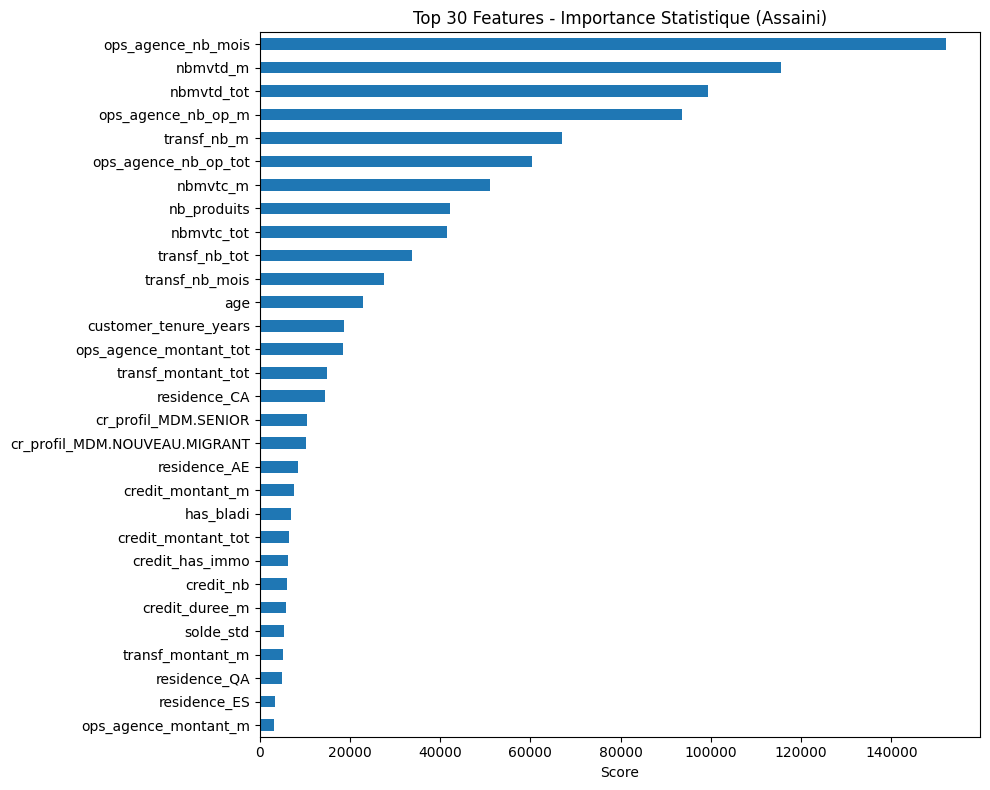


--- Importance RandomForest (Données Assainies) ---
  Entraînement RF pour importance (données assainies)...
  Entraînement terminé.

--- Top 30 Features (RF sur Données Assainies) ---
ops_agence_nb_op_tot             0.143371
ops_agence_nb_mois               0.121544
ops_agence_montant_tot           0.090859
ops_agence_nb_op_m               0.088661
ops_agence_montant_m             0.084866
age                              0.051178
mvtdeb_m                         0.032957
mvtdeb_tot                       0.031678
customer_tenure_years            0.029555
nbmvtd_m                         0.025671
mvtcred_m                        0.025433
mvtcred_tot                      0.024496
cr_profil_MDM.SENIOR             0.022925
nbmvtc_m                         0.021971
solde_std                        0.020559
transf_montant_tot               0.020542
nbmvtd_tot                       0.017220
nbmvtc_tot                       0.016864
solde_m                          0.014883
nb_produits     

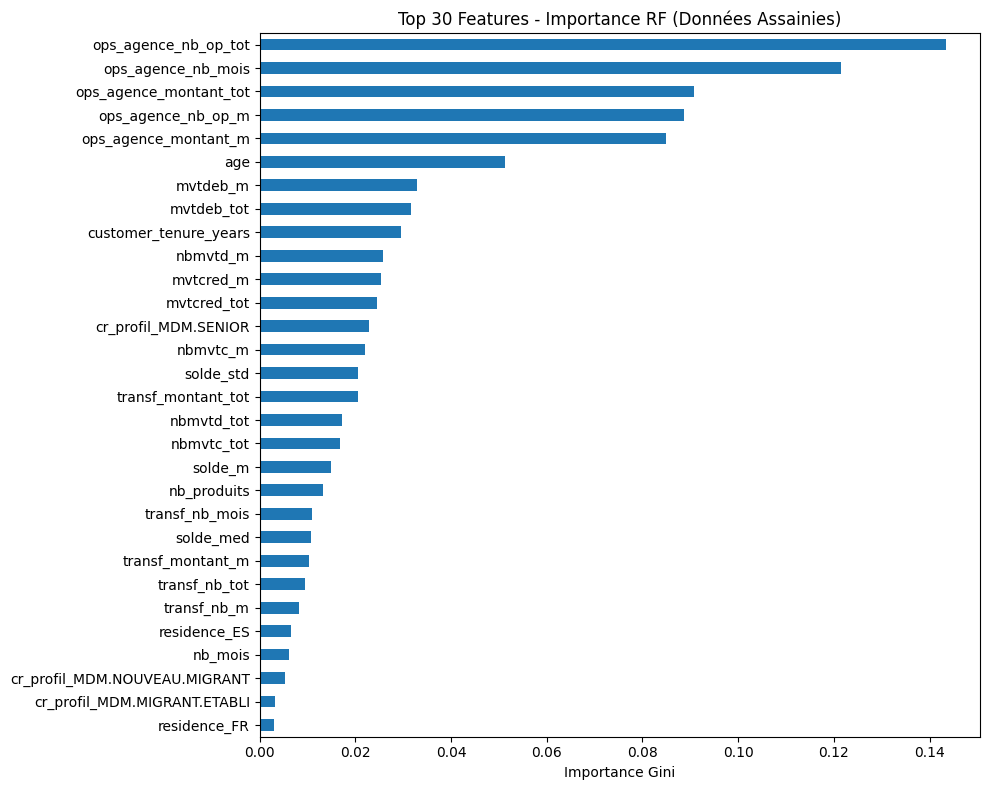

In [10]:
# =============================================================================
# PROCHAINE ÉTAPE : ANALYSE D'IMPORTANCE SUR DONNÉES ASSAINIES
# =============================================================================
print("\n--- Analyse d'Importance sur le Jeu de Features Assaini ---")

# Assurer que X_final_cleaned et y_final_cleaned sont disponibles
if 'X_final_cleaned' in locals() and 'y_final_cleaned' in locals() and not X_final_cleaned.empty:
    X_clean = X_final_cleaned.copy()
    y_clean = y_final_cleaned.copy()
    print(f"Analyse sur X_clean shape: {X_clean.shape}")

    # --- Analyse 1: Scores Statistiques sur X_clean ---
    print("\nAnalyse 1: Scores Statistiques (Données Assainies)...")
    numerical_cols_clean = X_clean.select_dtypes(include='float').columns
    categorical_bool_cols_clean = X_clean.select_dtypes(include='int').columns.tolist()

    scores_num_clean = pd.Series(dtype=float)
    if not numerical_cols_clean.empty:
        try:
            selector_num = SelectKBest(score_func=f_classif, k='all')
            selector_num.fit(X_clean[numerical_cols_clean].fillna(0), y_clean) # fillna par sécurité
            scores_num_clean = pd.Series(selector_num.scores_, index=numerical_cols_clean)
            print(f"  Scores F-value calculés pour {len(scores_num_clean)} colonnes numériques.")
        except Exception as e: print(f"  Erreur f_classif: {e}")

    scores_cat_clean = pd.Series(dtype=float)
    if categorical_bool_cols_clean:
         cols_for_chi2_clean = [c for c in categorical_bool_cols_clean if (X_clean[c] >= 0).all()]
         neg_cols = list(set(categorical_bool_cols_clean) - set(cols_for_chi2_clean))
         if neg_cols: print(f"  Colonnes exclues de Chi2 car négatives: {neg_cols}")
         if cols_for_chi2_clean:
              try:
                  selector_cat = SelectKBest(score_func=chi2, k='all')
                  selector_cat.fit(X_clean[cols_for_chi2_clean].fillna(0), y_clean) # fillna par sécurité
                  scores_cat_clean = pd.Series(selector_cat.scores_, index=cols_for_chi2_clean)
                  print(f"  Scores Chi2 calculés pour {len(scores_cat_clean)} colonnes catégorielles/booléennes.")
              except Exception as e: print(f"  Erreur chi2: {e}")
         else: print("  Aucune colonne valide trouvée pour Chi2.")
    else: print("  Aucune colonne int/bool trouvée pour Chi2.")

    all_scores_stat_clean = pd.concat([scores_num_clean, scores_cat_clean]).sort_values(ascending=False)
    print(f"\n--- Top {N_TOP_FEATURES_DISPLAY} Features (Stats sur Données Assainies) ---")
    if not all_scores_stat_clean.empty:
        print(all_scores_stat_clean.head(N_TOP_FEATURES_DISPLAY))
        # Visualisation
        plt.figure(figsize=(10, 8))
        all_scores_stat_clean.head(N_TOP_FEATURES_DISPLAY).sort_values(ascending=True).plot(kind='barh')
        plt.title(f'Top {N_TOP_FEATURES_DISPLAY} Features - Importance Statistique (Assaini)')
        plt.xlabel('Score')
        plt.tight_layout()
        plt.show()
    else: print("Aucun score statistique calculé.")


    # --- Analyse 2: Importance RandomForest sur X_clean ---
    print(f"\n--- Importance RandomForest (Données Assainies) ---")
    # Utiliser les hyperparamètres du modèle final si déjà optimisés, sinon garder ceux par défaut
    model_rf_importance_clean = RandomForestClassifier(n_estimators=100, random_state=42,
                                                     class_weight='balanced', # Important pour l'importance ici
                                                     n_jobs=-1, max_depth=15, min_samples_leaf=5)
    print("  Entraînement RF pour importance (données assainies)...")
    model_rf_importance_clean.fit(X_clean.fillna(0), y_clean) # fillna par sécurité
    print("  Entraînement terminé.")
    importances_rf_clean = pd.Series(model_rf_importance_clean.feature_importances_, index=X_clean.columns)
    top_importances_rf_clean = importances_rf_clean.sort_values(ascending=False)
    print(f"\n--- Top {N_TOP_FEATURES_DISPLAY} Features (RF sur Données Assainies) ---")
    print(top_importances_rf_clean.head(N_TOP_FEATURES_DISPLAY))

    # Visualisation
    plt.figure(figsize=(10, 8))
    top_importances_rf_clean.head(N_TOP_FEATURES_DISPLAY).sort_values(ascending=True).plot(kind='barh')
    plt.title(f'Top {N_TOP_FEATURES_DISPLAY} Features - Importance RF (Données Assainies)')
    plt.xlabel('Importance Gini')
    plt.tight_layout()
    plt.show()

else:
    print("Erreur: Variables X_final_cleaned ou y_final_cleaned non trouvées pour l'analyse d'importance.")



In [7]:
import os # Assurez-vous aussi que os est importé !
import pandas as pd # Et pandas etc. si nécessaire dans cette cellule
import numpy as np
from sklearn.preprocessing import PolynomialFeatures # Pour l'autre erreur potentielle

# --- Configuration Essentielle ---
DATA_PATH = "/home/kaoutar/Desktop/data/" # Chemin Corrigé
OUTPUT_PATH = DATA_PATH
# Nom du fichier résultant de l'Étape III (à charger)
FOUND_FILE_PATH = os.path.join(DATA_PATH, 'dataset_final_engineered_complet.csv')
# -----------------------------

print(f"Configuration chargée. DATA_PATH = {DATA_PATH}")

# --- Charger les données (si pas déjà en mémoire) ---
if 'df_engineered' not in locals() or df_engineered.empty:
    if os.path.exists(FOUND_FILE_PATH):
        print(f"Chargement de {FOUND_FILE_PATH} dans df_engineered...")
        df_engineered = pd.read_csv(FOUND_FILE_PATH)
        print(f"Chargement réussi. Shape: {df_engineered.shape}")
    else:
        raise FileNotFoundError(f"Le fichier {FOUND_FILE_PATH} n'existe pas. Exécutez d'abord les étapes précédentes.")
elif not isinstance(df_engineered, pd.DataFrame) or df_engineered.empty:
     raise ValueError("df_engineered existe mais n'est pas un DataFrame valide ou est vide.")
else:
     print(f"Utilisation de df_engineered déjà en mémoire (Shape: {df_engineered.shape}).")

# Préparer X_fe et y_fe
if 'appetent' in df_engineered.columns:
    X_fe = df_engineered.drop('appetent', axis=1).copy()
    y_fe = df_engineered['appetent'].copy()
    print(f"Préparation X_fe/y_fe OK. Shape X_fe: {X_fe.shape}")
else:
    raise ValueError("Colonne 'appetent' manquante dans df_engineered.")

# ... Maintenant vous pouvez exécuter le bloc de FE supplémentaire ...
# --- Idée 1 : Binning de l'Âge ---
# ... etc ...

Configuration chargée. DATA_PATH = /home/kaoutar/Desktop/data/
Chargement de /home/kaoutar/Desktop/data/dataset_final_engineered_complet.csv dans df_engineered...
Chargement réussi. Shape: (1051281, 98)
Préparation X_fe/y_fe OK. Shape X_fe: (1051281, 97)


In [8]:

import os
# --- Assurez-vous que le DataFrame est chargé ---
# (Normalement fait par le bloc de vérification précédent)
if 'df_check' in locals() and isinstance(df_check, pd.DataFrame):
    df_engineered = df_check.copy() # Utiliser df_engineered pour la suite
    print(f"Utilisation du DataFrame chargé (Shape: {df_engineered.shape}) pour FE supplémentaire.")
else:
    # Recharger si nécessaire (adapter le nom du fichier si besoin)
    FOUND_FILE = os.path.join(DATA_PATH, 'dataset_final_engineered_complet.csv')
    if os.path.exists(FOUND_FILE):
         print(f"Rechargement de {FOUND_FILE} dans df_engineered...")
         df_engineered = pd.read_csv(FOUND_FILE)
    else:
         raise FileNotFoundError("Impossible de trouver ou charger le fichier de base pour le FE supplémentaire.")

# Séparer X et y pour le FE
if 'appetent' in df_engineered.columns:
    X_fe = df_engineered.drop('appetent', axis=1).copy()
    y_fe = df_engineered['appetent'].copy() # Garder y de côté
    print(f"Préparation pour FE supplémentaire - X_fe Shape: {X_fe.shape}")
else:
    raise ValueError("Colonne 'appetent' manquante dans df_engineered.")


# --- Idée 1 : Binning de l'Âge ---
print("\n1. Binning de l'âge...")
if 'age' in X_fe.columns:
    try:
        age_bins = [0, 18, 25, 35, 45, 55, 65, 75, 130]
        age_labels = ['0-18', '19-25', '26-35', '36-45', '46-55', '56-65', '66-75', '75+']
        X_fe['age_group'] = pd.cut(X_fe['age'], bins=age_bins, labels=age_labels, right=True, include_lowest=True)
        print("  Colonne 'age_group' créée.")

        # Appliquer One-Hot Encoding aux groupes d'âge
        age_group_encoded = pd.get_dummies(X_fe['age_group'], prefix='age_group', dummy_na=False).astype(int)
        X_fe = pd.concat([X_fe, age_group_encoded], axis=1)
        X_fe = X_fe.drop('age_group', axis=1) # Supprimer la version catégorielle
        # Optionnel: Supprimer 'age' numérique si vous ne voulez QUE les groupes
        # X_fe = X_fe.drop('age', axis=1)
        print(f"  Groupes d'âge encodés. Nouvelles colonnes: ~{len(age_labels)}")
    except Exception as e: print(f"  Erreur binning âge: {e}")
else: print("  Colonne 'age' non trouvée.")


# --- Idée 2 : Création de Ratios Financiers ---
print("\n2. Création de Ratios...")
# Utiliser les noms de colonnes SANS préfixes (basé sur votre dernier output)
mvtcred_tot_col = 'mvtcred_tot'
mvtdeb_tot_col = 'mvtdeb_tot'
ops_agence_montant_tot_col = 'ops_agence_montant_tot'
ops_agence_nb_op_tot_col = 'ops_agence_nb_op_tot'
credit_montant_tot_col = 'credit_montant_tot'
credit_nb_col = 'credit_nb'

# Ratio Débit/Crédit Total
if mvtcred_tot_col in X_fe.columns and mvtdeb_tot_col in X_fe.columns:
    denominator = X_fe[mvtcred_tot_col].replace(0, np.nan)
    X_fe['ratio_debit_credit_tot'] = X_fe[mvtdeb_tot_col] / denominator
    X_fe['ratio_debit_credit_tot'] = X_fe['ratio_debit_credit_tot'].fillna(0).replace(np.inf, 0)
    print("  Feature 'ratio_debit_credit_tot' créée.")

# Montant moyen par opération agence
if ops_agence_montant_tot_col in X_fe.columns and ops_agence_nb_op_tot_col in X_fe.columns:
    denominator = X_fe[ops_agence_nb_op_tot_col].replace(0, np.nan)
    X_fe['avg_amount_per_ops_agence'] = X_fe[ops_agence_montant_tot_col] / denominator
    X_fe['avg_amount_per_ops_agence'] = X_fe['avg_amount_per_ops_agence'].fillna(0).replace(np.inf, 0)
    print("  Feature 'avg_amount_per_ops_agence' créée.")

# Montant moyen par crédit
if credit_montant_tot_col in X_fe.columns and credit_nb_col in X_fe.columns:
    denominator = X_fe[credit_nb_col].replace(0, np.nan)
    X_fe['avg_amount_per_credit'] = X_fe[credit_montant_tot_col] / denominator
    X_fe['avg_amount_per_credit'] = X_fe['avg_amount_per_credit'].fillna(0).replace(np.inf, 0)
    print("  Feature 'avg_amount_per_credit' créée.")


# --- Idée 3 : Création de Features d'Interaction ---
print("\n3. Création de Features d'Interaction...")

# Interaction Age x Tenure (polynomial)
if 'age' in X_fe.columns and 'customer_tenure_years' in X_fe.columns:
    try:
        poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
        X_num_interact = X_fe[['age', 'customer_tenure_years']].fillna(0)
        poly_features = poly.fit_transform(X_num_interact)
        poly_feature_names = poly.get_feature_names_out(['age', 'customer_tenure_years'])
        df_poly = pd.DataFrame(poly_features, columns=poly_feature_names, index=X_fe.index)
        # Ajouter seulement les termes d'ordre 2 (carrés et interaction)
        # Les termes d'ordre 1 sont déjà présents (age, customer_tenure_years)
        cols_to_add = [c for c in df_poly.columns if '^2' in c or '*' in c or ' ' in c] # Noms générés par get_feature_names_out
        X_fe = pd.concat([X_fe, df_poly[cols_to_add]], axis=1)
        print(f"  Features polynomiales/interaction créées pour Age/Tenure: {cols_to_add}")
    except Exception as e: print(f"  Erreur création features polynomiales: {e}")

# Interaction Manuelle : Age x Profil Senior
profil_senior_col = 'cr_profil_MDM.SENIOR' # Vérifiez ce nom exact
if 'age' in X_fe.columns and profil_senior_col in X_fe.columns:
    X_fe['age_x_profil_senior'] = X_fe['age'] * X_fe[profil_senior_col]
    print(f"  Feature d'interaction 'age_x_profil_senior' créée.")

# Interaction Tenure x Profil Nouveau Migrant
profil_new_migrant_col = 'cr_profil_MDM.NOUVEAU.MIGRANT' # Vérifiez ce nom exact
if 'customer_tenure_years' in X_fe.columns and profil_new_migrant_col in X_fe.columns:
    X_fe['tenure_x_profil_newmigrant'] = X_fe['customer_tenure_years'] * X_fe[profil_new_migrant_col]
    print(f"  Feature d'interaction 'tenure_x_profil_newmigrant' créée.")


# --- Finalisation après Ajout de Features ---
print(f"\nShape finale de X_fe après ajout de features: {X_fe.shape}")
# Vérifier NaNs/Infs introduits (surtout par les ratios)
nan_inf_check = X_fe.isna().sum().sum() + np.isinf(X_fe.select_dtypes(include=np.number)).sum().sum()
if nan_inf_check > 0:
    print(f"  ATTENTION : {nan_inf_check} NaNs ou Infs détectés après FE supplémentaire ! Remplissage par 0...")
    X_fe = X_fe.replace([np.inf, -np.inf], np.nan)
    X_fe = X_fe.fillna(0) # Remplissage simple, à affiner si nécessaire

# S'assurer que toutes les colonnes sont numériques
non_numeric_final = X_fe.select_dtypes(exclude=[np.number]).columns
if len(non_numeric_final) > 0:
     print(f"  ATTENTION: Colonnes non numériques restantes après FE: {non_numeric_final.tolist()}. Tentative de conversion...")
     for col in non_numeric_final:
         try:
             X_fe[col] = pd.to_numeric(X_fe[col], errors='coerce').fillna(0)
         except:
              print(f"  Impossible de convertir {col}, suppression...")
              X_fe = X_fe.drop(columns=[col])

print("\n--- Feature Engineering Supplémentaire Terminé ---")
print("DataFrame 'X_fe' contient maintenant les features originales assainies + les nouvelles.")
print("Variable 'y_fe' contient la cible.")

# --- Étape Suivante Essentielle ---
print("\nPROCHAINE ÉTAPE CRUCIALE : Appliquer la Sélection Stricte (Objectif A) sur X_fe")
print("Il faut maintenant définir la liste 'cols_to_remove_strict...' et créer 'X_final_cleaned' à partir de 'X_fe' avant de passer aux étapes V et VI.")

# Exemple rapide pour montrer la sélection (à intégrer dans la suite)
# cols_to_remove_strict_exact_names = [ ... liste des 19 colonnes leaky ... ]
# cols_final_strict = [c for c in X_fe.columns if c not in cols_to_remove_strict_exact_names]
# X_final_strict_version = X_fe[cols_final_strict]
# print(f"Shape de X après sélection stricte (exemple): {X_final_strict_version.shape}")

Rechargement de /home/kaoutar/Desktop/data/dataset_final_engineered_complet.csv dans df_engineered...
Préparation pour FE supplémentaire - X_fe Shape: (1051281, 97)

1. Binning de l'âge...
  Colonne 'age_group' créée.
  Groupes d'âge encodés. Nouvelles colonnes: ~8

2. Création de Ratios...
  Feature 'ratio_debit_credit_tot' créée.
  Feature 'avg_amount_per_ops_agence' créée.
  Feature 'avg_amount_per_credit' créée.

3. Création de Features d'Interaction...
  Features polynomiales/interaction créées pour Age/Tenure: ['age^2', 'age customer_tenure_years', 'customer_tenure_years^2']
  Feature d'interaction 'age_x_profil_senior' créée.
  Feature d'interaction 'tenure_x_profil_newmigrant' créée.

Shape finale de X_fe après ajout de features: (1051281, 113)

--- Feature Engineering Supplémentaire Terminé ---
DataFrame 'X_fe' contient maintenant les features originales assainies + les nouvelles.
Variable 'y_fe' contient la cible.

PROCHAINE ÉTAPE CRUCIALE : Appliquer la Sélection Stricte (Ob

In [9]:
ENHANCED_FEATURES_FILE = os.path.join(OUTPUT_PATH, 'X_fe_enhanced_110cols.parquet') # Utiliser Parquet (plus efficace) ou .csv
TARGET_FILE = os.path.join(OUTPUT_PATH, 'y_fe_enhanced_target.csv')

print(f"\nSauvegarde des features enrichies X_fe dans: {ENHANCED_FEATURES_FILE}")
try:
    X_fe.to_parquet(ENHANCED_FEATURES_FILE, index=False) # Sauvegarde Parquet
    # Ou en CSV : X_fe.to_csv(ENHANCED_FEATURES_FILE, index=False, sep=',')
    print("  Sauvegarde X_fe réussie.")
except Exception as e:
    print(f"  ERREUR sauvegarde X_fe: {e}")

print(f"\nSauvegarde de la cible y_fe dans: {TARGET_FILE}")
try:
    y_fe.to_csv(TARGET_FILE, index=False, header=True) # Garder l'en-tête pour la série
    print("  Sauvegarde y_fe réussie.")
except Exception as e:
    print(f"  ERREUR sauvegarde y_fe: {e}")
# ---------------------------------------------------------------------


Sauvegarde des features enrichies X_fe dans: /home/kaoutar/Desktop/data/X_fe_enhanced_110cols.parquet
  Sauvegarde X_fe réussie.

Sauvegarde de la cible y_fe dans: /home/kaoutar/Desktop/data/y_fe_enhanced_target.csv
  Sauvegarde y_fe réussie.
